# PREDICCIÓN COSTE ESPERADO DEL SEGURO

Con el objetivo de estimar, mediante un modelo predictivo, el coste esperado del seguro en
función de las variables que considerén oportunas, se procedera a crear diferentes tipos de modelos y se hará una comparación para determinar cual usar para dicho objetivo, nuestra variable objetivo (coste esperado) en este caso es la variable "Prima"


| Nombre                 | Definición                                                                                  |
|------------------------|---------------------------------------------------------------------------------------------|
| ID                     | Identificador único del préstamo.                                                           |
| Edad                   | Edad del prestatario.                                                                       |
| Ingresos               | Ingreso anual del prestatario.                                                              |
| Monto_Inicial          | Cantidad de dinero acordada.                                                                |
| Scoring_Crediticio     | Puntuación crediticia del prestatario que indica su solvencia.                              |
| Meses_Empleo           | Número de meses de vida laboral del prestatario.                                            |
| Num_Creditos           | Número de líneas de crédito abiertas del prestatario.                                       |
| Ratio_Interes          | Ratio de interés del préstamo (multiplicado por 100).                                       |
| Duracion               | Duración del préstamo en meses.                                                             |
| Ratio_Deuda_Ingresos   | Ratio de deuda frente a ingresos, que indica la deuda del prestatario en comparación con sus ingresos. |
| Estudios               | Nivel más alto de educación alcanzado por el prestatario.                                   |
| Tipo_Jornada_Laboral   | Tipo de jornada laboral del prestatario.                                                    |
| Estado_Civil           | Estado civil del prestatario.                                                               |
| Posesion_Hipoteca      | Indicador de si el prestatario posee una hipoteca.                                          |
| Personas_Cargo         | Número de personas a cargo del prestatario.                                                 |
| Proposito              | Propósito para el cual se solicita el préstamo.                                             |
| Fiador                 | Indicador de si el prestatario dispone de cofirmante o fiador.                              |
| Impago                 | Variable objetivo binaria que indica si el préstamo entró en mora (1) o no (0).            |
| Prima                  | Prima de la póliza de protección de pagos.                                                  |

## REGRESIÓN LINEAL MULTIPLE

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

Reutilizamos un dataframe, el cual se ha utilizado para cumplir el objetivo Nº2, ya que nos servira para nuestro modelo predictivo, tenemos los resultados de las probabilidades de pago e impago y transformadas ya a numericas posibles variables a utilizar en este modelo que en un primer momento eran strings

In [2]:
CARPETA = "data"
FICHERO = "df_prob.csv"
df = pd.read_csv(os.path.join(CARPETA, FICHERO))

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,65.85,0,0,0,0,1,0,0.392497,0.607503,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,260.60,0,0,1,0,0,0,0.348994,0.651006,1
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,221.02,0,1,0,0,0,0,0.659043,0.340957,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,125.00,0,1,0,0,0,0,0.495953,0.504047,1
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,800.00,0,0,0,0,0,0,0.433751,0.566249,1


## 1. Análisis exploratorio

Hacemos un análisis exploratorio para ver el tipo de datos que tenemos, si hay nulos, la media, la desviación estandar, la mediana y asi podremos saber como hacer un correcto uso de ellos para nuestro modelo predictivo

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101895 entries, 0 to 101894
Data columns (total 26 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   ID                                   101895 non-null  str    
 1   Edad                                 101895 non-null  int64  
 2   Ingresos                             101895 non-null  float64
 3   Monto_Inicial                        101895 non-null  int64  
 4   Scoring_Crediticio                   101895 non-null  int64  
 5   Meses_Empleo                         101895 non-null  float64
 6   Num_Creditos                         101895 non-null  int64  
 7   Ratio_Interes                        101895 non-null  float64
 8   Duracion                             101895 non-null  float64
 9   Ratio_Deuda_Ingresos                 101895 non-null  float64
 10  Estado_Civil                         101895 non-null  float64
 11  Posesion_Hipoteca       

In [4]:
df.describe()

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estado_Civil,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
count,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,...,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000
mean,39.665666,41502.987271,45009.339889,692.304549,212.911409,1.998135,10.670103,37.251065,0.321381,1.115383,...,384.706766,0.079454,0.372138,0.159390,0.148506,0.099504,0.201924,0.542098,0.457902,0.400815
std,10.103095,16034.114815,46629.197358,87.517169,151.093061,0.998260,3.797959,14.155323,0.181193,0.689165,...,267.147571,0.270448,0.483377,0.366041,0.355602,0.299340,0.401437,0.159452,0.159452,0.490066
min,19.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000,2.010000,12.000000,0.100000,0.000000,...,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.077652,0.064705,0.000000
25%,33.000000,30468.000000,14994.000000,636.000000,69.000000,1.000000,7.960000,24.000000,0.140000,1.000000,...,137.465000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.422543,0.335729,0.000000
50%,40.000000,39082.000000,40000.000000,704.000000,208.000000,2.000000,10.600000,36.000000,0.290000,1.000000,...,336.270000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.546253,0.453747,0.000000
75%,46.000000,50137.500000,47396.500000,761.000000,337.000000,3.000000,13.260000,48.000000,0.550000,2.000000,...,610.695000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.664271,0.577457,1.000000
max,64.000000,120000.000000,400000.000000,845.000000,628.000000,4.000000,24.440000,60.000000,0.550000,2.000000,...,800.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.935295,0.922348,1.000000


Observamos la distribución de la variable "Prima" que es la que queremos predecir

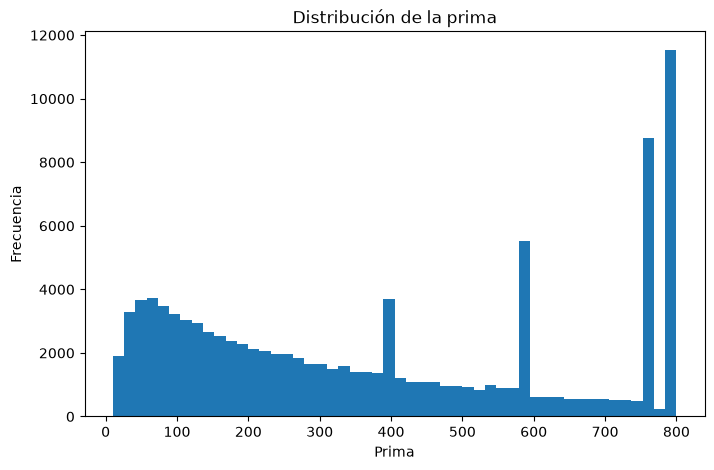

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["Prima"], bins=50)

plt.xlabel("Prima")
plt.ylabel("Frecuencia")
plt.title("Distribución de la prima")

plt.show()

Observamos que la Prima está truncada en 800, es decir, las primas mayores a ese valor por lo que sea se quedan con el valor de 800, no existen valores más altos de ese valor en nuestro dataset, por lo que probamos a eliminarlas y continuaremos con el proceso si al eliminarlas no nos desacemos de la gran mayoria de nuestros datos.

PD: Hemos probado el modelo borrando todas las primas igual o mayores a 800 y tambien quedandonos con un porcentaje menor de Primas = 800, y en los dos casos el modelo rendia peor, asi que, hemos mantenido la idea principal y no vamos a borrar datos de la variable Y

In [6]:
#df = df[df["Prima"] <= 800]

In [7]:
#df = df.sample(frac=0.4, random_state=42)

Observamos que solo borrariamos un 11% de nuestro dataset por lo que decidimos continuar con el proceso

In [8]:
#n_filas = (df["Prima"] == 800).sum()
#print(f"Filas a borrar: {n_filas}")


#print(f"Porcentaje: {n_filas / len(df):.2%}")

In [9]:
print(f"Filas y columnas: {df.shape}")
print(f"\nColumnas: {df.columns.tolist()}")

Filas y columnas: (101895, 26)

Columnas: ['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estado_Civil', 'Posesion_Hipoteca', 'Personas_Cargo', 'Proposito', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado', 'Estudios_Grado Universitario', 'Estudios_Máster', 'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Tiempo parcial', 'prob_pago', 'prob_impago', 'prediccion']


Creamos una matriz de correlación para ver que variables tienen relación con nuestra variable objetivo "Prima", con el fin de hacer una selección final para poder separar en X e Y, y obetener las variables que influiran en nuestro modelo.

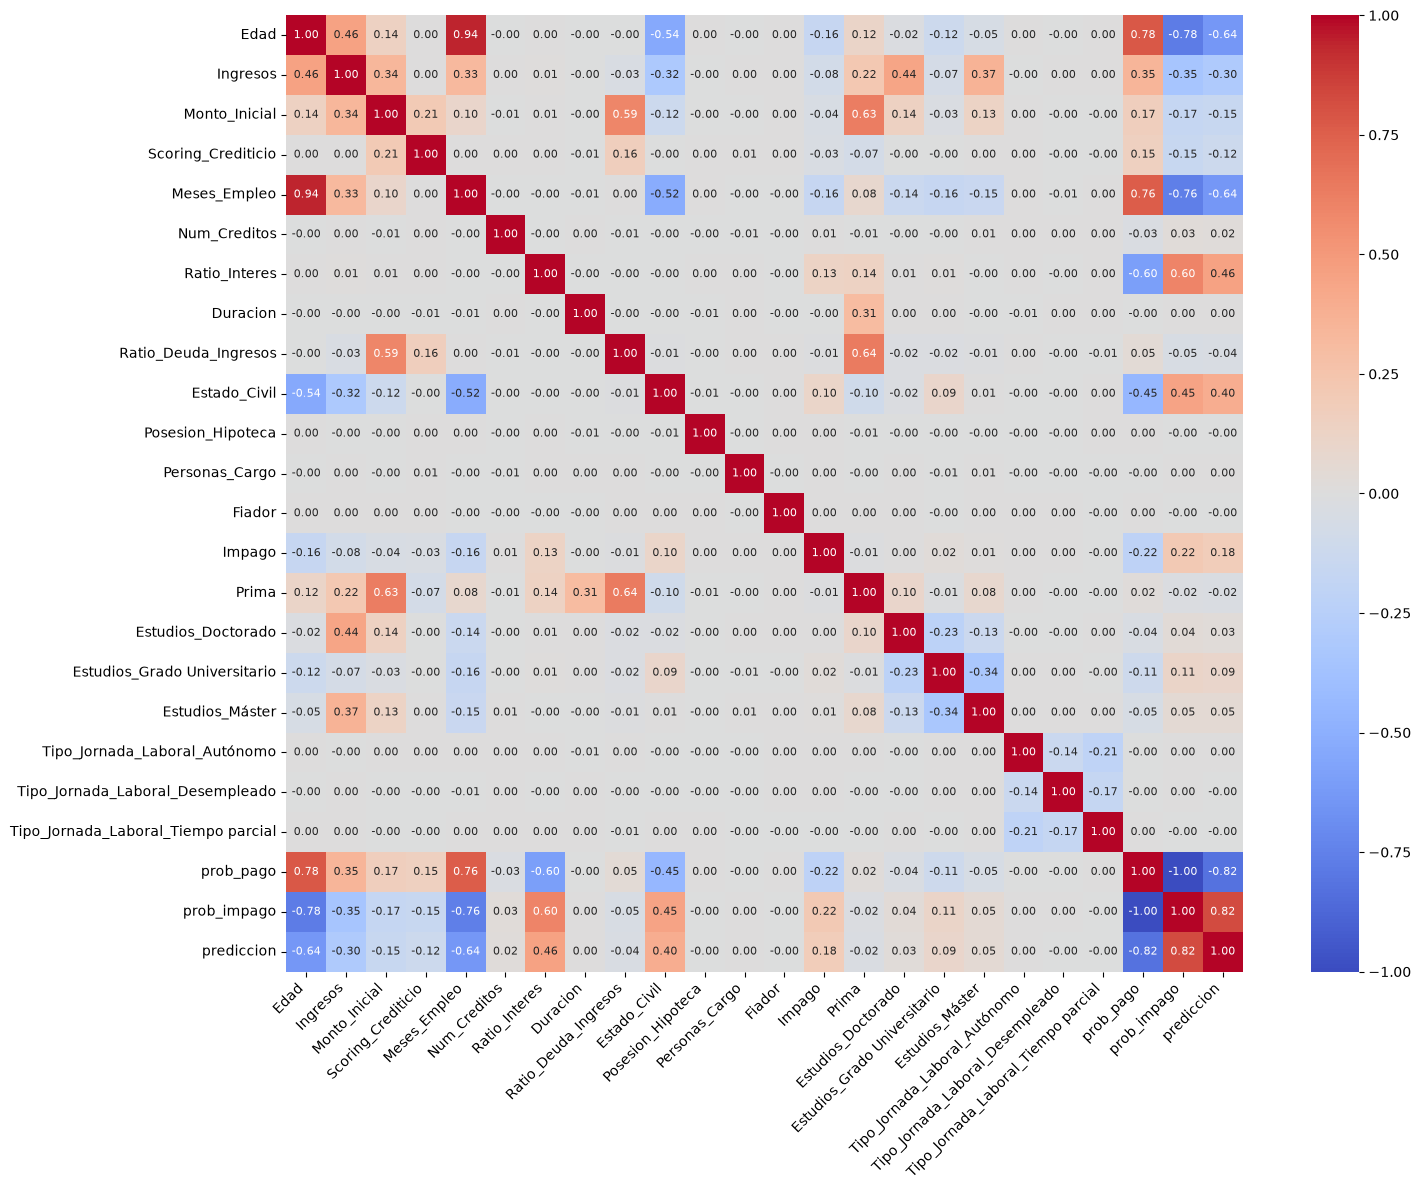

In [10]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(16,12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    annot_kws={"size": 8}
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Para una mejor visualización vamos a hacer un heatmap pero solo con la variable objetivo en nuestro caso la variable "Prima", con esto sera mucho más visibles cuales son las variables a elegir.

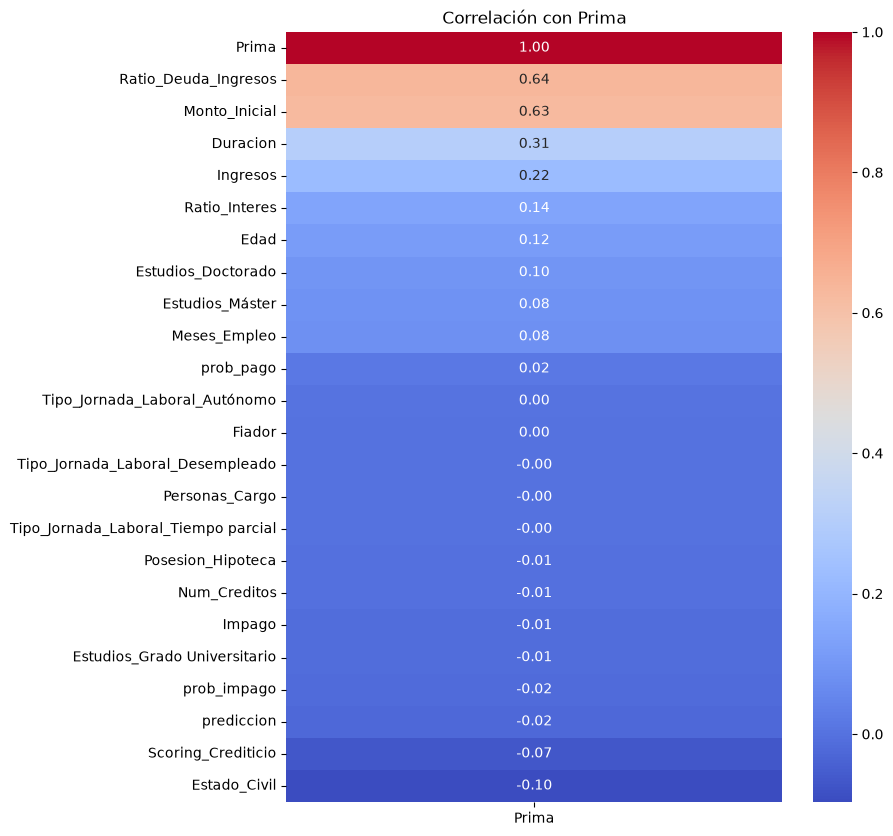

In [11]:
corr_prima = (
    df.corr(numeric_only=True)["Prima"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,10))
sns.heatmap(
    corr_prima.to_frame(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlación con Prima")
plt.show()

Resultados númericos de las correlaciones con la variable objetivo

In [12]:
corr_prima = (
    df.corr(numeric_only=True)["Prima"]
    .drop("Prima")
    .abs()
    .sort_values(ascending=False)
)

print(corr_prima)

Ratio_Deuda_Ingresos                   0.636085
Monto_Inicial                          0.626538
Duracion                               0.305995
Ingresos                               0.222311
Ratio_Interes                          0.139729
Edad                                   0.115464
Estado_Civil                           0.096761
Estudios_Doctorado                     0.095346
Estudios_Máster                        0.084178
Meses_Empleo                           0.080449
Scoring_Crediticio                     0.070524
prediccion                             0.024278
prob_impago                            0.016378
prob_pago                              0.016378
Estudios_Grado Universitario           0.013675
Impago                                 0.012099
Num_Creditos                           0.006755
Posesion_Hipoteca                      0.005850
Tipo_Jornada_Laboral_Tiempo parcial    0.002223
Tipo_Jornada_Laboral_Autónomo          0.002000
Fiador                                 0

Ahora hacemos la selección de variables y sepramos en train y test, separamos nuestro conjunto de df para entrenar con el 80% de los datos y usamos el 20% de test para predecir y testear nuestro modelo

Se ha decidido incluir la probabilidad de impago a pesar de un resultado no muy optimo en la correlación, ya que debria de ser totalmente proporcional a la prima, si la aseguradora Lagunaro cree que pagaras entonces la prima sera menor, en el caso contrario, si hay un riesgo alto de impago, pagaras más.

In [13]:
X = X = df[
    [
        "Ratio_Deuda_Ingresos",
        "Monto_Inicial",
        "Duracion",
        "Ingresos",
        "prob_impago"
    ]
]
y = df["Prima"]

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.8, random_state = 42, shuffle = True)

Estandarizamos las variables para que todas estén en una escala similar y ninguna tenga más influencia en el modelo solo por tener valores más grandes. Así conseguimos un modelo más estable, con resultados más fiables y una comparación más justa entre las variables.

In [15]:
from sklearn.preprocessing import StandardScaler
std_scaler = StandardScaler()
std_scaler.set_output(transform="pandas")
X_train_scaled = std_scaler.fit_transform(X_train)


In [16]:
X_train_scaled

,Ratio_Deuda_Ingresos,Monto_Inicial,Duracion,Ingresos,prob_impago
78621,-1.222560,-0.778663,1.607227,-0.317057,1.054548
21210,-1.222560,-0.662677,1.607227,-0.042566,0.255287
90376,-0.615512,-0.109650,0.759975,0.023095,0.269558
35089,-0.339581,-0.156883,1.607227,-0.316808,-0.028779
18600,-1.167373,-0.109650,1.607227,2.260059,-0.807971
...,...,...,...,...,...
6265,-1.222560,-0.827798,-0.087277,-0.335328,-0.306084
54886,-0.946629,-0.484775,-0.087277,-0.270166,0.260736
76820,1.260816,0.716106,1.607227,0.647280,-0.029720
860,0.212280,-0.857676,-0.087277,-1.589122,1.304342


## 2. Creamos el modelo de regresión lineal

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_squared_error, mean_absolute_error

modelo = LinearRegression()
modelo.fit(X = X_train_scaled, y = y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[122.91, 85.44, 82.1 , 45.1 , 30.58]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Ratio_Deuda_Ingresos','Monto_Inicial','Duracion','Ingresos', 'prob_impago']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,385.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


Se crea una tabla con los coeficientes obtenidos por el modelo para identificar la influencia de cada variable sobre la prima. Además, se calcula el coeficiente de determinación (R²) para evaluar qué porcentaje de la variabilidad de la prima es explicado por el modelo. Esto facilita la interpretación y evaluación de los resultados obtenidos.

In [18]:
def data_frame_maker(model):
    coef_dict = {}
    coef_dict["intercepto"] = model.intercept_
    for i in range(1,len(model.feature_names_in_)):
        coef_dict[model.feature_names_in_[i]] = model.coef_[i]

    return pd.DataFrame(
        list(coef_dict.items()), columns=["Feature", "Coeficiente"]
    )

print(data_frame_maker(modelo))
print(f"Coeficiente de determinación R^2:", modelo.score(X_train_scaled, y_train))

         Feature  Coeficiente
0     intercepto   385.121050
1  Monto_Inicial    85.438114
2       Duracion    82.101819
3       Ingresos    45.101020
4    prob_impago    30.583139
Coeficiente de determinación R^2: 0.623810888612569


El modelo explica aproximadamente el 62,4 % de la variabilidad de la prima (R² = 0,624), lo que indica un ajuste aceptable. Al haber estandarizado las variables, los coeficientes son comparables entre sí. Las variables con mayor influencia en la prima son Monto_Inicial (85,44) y Duracion (82,10), seguidas de Ingresos (45,10) y prob_impago (30,58).

In [19]:
# Estandarizar los valores de X_test
X_test_scaled = std_scaler.transform(X_test)

Obtenemos las siguientes metricas que nos darán diferentes conclusiones

In [20]:
predicciones = modelo.predict(X=X_test_scaled)
mse = mean_squared_error(y_true=y_test, y_pred=predicciones)
rmse = root_mean_squared_error(y_true=y_test, y_pred=predicciones)
msa = mean_absolute_error(y_true=y_test, y_pred=predicciones)
print(f"Primeras cinco predicciones: {predicciones[0:5]}")
print(f"El error (mse) de test es: {round(mse,2)}")
print(f"El error (rmse) de test es: {round(rmse,2)}")
print(f"El error (msa) de test es: {round(msa,2)}")

Primeras cinco predicciones: [612.34351321 140.7802367  394.98354463 271.00774223 943.78515399]
El error (mse) de test es: 27296.98
El error (rmse) de test es: 165.22
El error (msa) de test es: 131.74


## 3. Metricas de error

El modelo realiza predicciones razonablemente cercanas a los valores reales. En el conjunto de prueba obtiene un error cuadrático medio (MSE) de 27.296,98 y una raíz del error cuadrático medio (RMSE) de 165,22, lo que indica que las predicciones se desvían en promedio unos 165 € aproximadamente del valor real de la prima. Además, el error absoluto medio (MAE) es de 131,74 €, por lo que el error medio de las predicciones es de unos 132 €. Estos resultados muestran un rendimiento aceptable, aunque todavía existe margen de mejora en la precisión del modelo.

Creamos el modelo con statsmodel

In [21]:
import statsmodels.api as sm

X_train_scaled = sm.add_constant(X_train_scaled, prepend=True)
modelo = sm.OLS(endog=y_train, exog=X_train_scaled)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.624
Model:                            OLS   Adj. R-squared:                  0.624
Method:                 Least Squares   F-statistic:                 2.703e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:54:31   Log-Likelihood:            -5.3131e+05
No. Observations:               81516   AIC:                         1.063e+06
Df Residuals:                   81510   BIC:                         1.063e+06
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  385.1211 

Todas las variables incluidas son estadísticamente significativas (p < 0,001), por lo que contribuyen a la predicción de la prima. Además, el valor F-statistic y su significancia indican que el modelo es globalmente significativo y las variables seleccionadas ayudan a explicar la variable objetivo.

Visualizamos los intervalos de confianza

In [22]:
intervalos_ci = modelo.conf_int(alpha=0.05)
intervalos_ci.columns = ['2.5%', '97.5%']
intervalos_ci

,2.5%,97.5%
const,383.996171,386.245929
Ratio_Deuda_Ingresos,121.444361,124.368685
Monto_Inicial,83.884974,86.991255
Duracion,80.976927,83.226710
Ingresos,43.783996,46.418043
prob_impago,29.381336,31.784943


existe una alta confianza en que todas las variables contribuyen positivamente a la explicación de la prima, siendo Ratio_Deuda_Ingresos, Monto_Inicial y Duracion las que presentan una mayor influencia en el modelo.

### Diagnostico

In [23]:
prediccion_train_scaled = modelo.predict(exog=X_train_scaled)
residuos_train_scaled = prediccion_train_scaled - y_train

C:\Users\mikel\AppData\Local\Temp\ipykernel_17796\4158859051.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', color = 'black', lw=2)


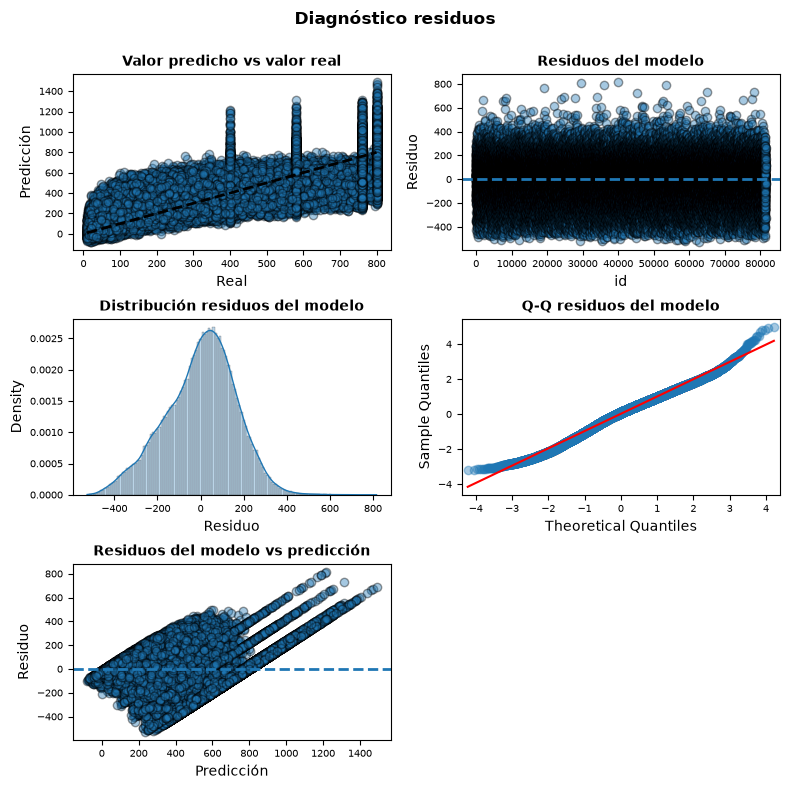

In [24]:
# Gráficos
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8))

axes[0, 0].scatter(y_train, prediccion_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train_scaled,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train_scaled,
    fit   = True, # estandariza los residuos con su ppropia media y desviación típica
    line  = 'q',
    ax    = axes[1, 1], 
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train_scaled, residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2, 1])
fig.tight_layout() # Recoloca automáticamente los gráficos para que títulos y etiquetas no se solapen
plt.subplots_adjust(top=0.9) # Deja libre el 10% superior de la figura para el título general
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");


Los gráficos muestran que el modelo sigue la tendencia general de los datos, aunque existe dispersión entre los valores reales y predichos. Los residuos se distribuyen alrededor de cero, lo que indica que no hay un sesgo claro en las predicciones. La distribución de los residuos es aproximadamente normal, aunque el gráfico Q-Q muestra ligeras desviaciones en los extremos. Además, se aprecia cierta variabilidad no constante en los residuos para algunas predicciones, por lo que el ajuste es razonable, pero no perfecto.

### Test Normalidad

In [25]:
from scipy import stats

shapiro_test = stats.shapiro(residuos_train_scaled)
shapiro_test

c:\Users\mikel\Desktop\RETOS\RETO 5\Equipo-Morado\retos\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 81516.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9927221863373431), pvalue=np.float64(3.1236457213637053e-49))

El test de Shapiro-Wilk obtiene un estadístico de 0,993 y un p-valor muy próximo a 0, por lo que se rechaza la hipótesis de normalidad de los residuos. Sin embargo, debido al gran tamaño de la muestra (más de 80.000 observaciones), pequeñas desviaciones de la normalidad resultan significativas. Por ello, es recomendable complementar este resultado con el histograma y el gráfico Q-Q, que muestran una distribución aproximadamente normal con ligeras desviaciones en los extremos.

In [26]:
k2, p_value = stats.normaltest(residuos_train_scaled)
print(f"Estadítico= {k2}, p-value = {p_value}")

Estadítico= 821.6050543425564, p-value = 3.896990056035387e-179


### Predicciones

In [27]:
predicciones = modelo.get_prediction(exog = X_train_scaled).summary_frame(alpha=0.05)
predicciones.head(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
78621,318.240992,1.415800,315.466033,321.015951,-2.935305,639.417289
21210,316.086622,1.300235,313.538170,318.635073,-5.087798,637.261042
90376,371.783152,0.841786,370.133257,373.433047,50.614605,692.951699
35089,446.768226,1.130881,444.551708,448.984745,125.596269,767.940184


Los intervalos de confianza de las predicciones son relativamente estrechos para la media estimada, lo que indica que el modelo realiza estimaciones estables. Sin embargo, los intervalos de predicción para observaciones individuales son bastante más amplios, reflejando la variabilidad existente en los datos. En conjunto, el modelo permite obtener predicciones razonables de la prima, aunque existe incertidumbre significativa al estimar casos concretos.

### Error de Test

In [28]:
X_test_scaled = sm.add_constant(X_test_scaled, prepend=True)
predicciones = modelo.predict(exog = X_test_scaled)
rmse = root_mean_squared_error(y_true=y_test, y_pred=predicciones)
print(f"El error (rmse) de test es: {round(rmse, 2)}")

El error (rmse) de test es: 165.22


Como bien hemos mencionado anteriormente, el modelo obtiene un RMSE de 165,22 en el conjunto de prueba, lo que significa que las predicciones se desvían del valor real de la prima en aproximadamente 165 € de media. Este resultado indica que el modelo presenta una capacidad predictiva aceptable, aunque todavía existe un margen de error considerable en algunas predicciones.

Como existe margen de mejora, se procedera a la creación de un modelo polinomico y se procedera a compararlos

# REGRESIÓN POLINÓMICA

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [30]:
CARPETA = "data"
FICHERO = "df_prob.csv"
df_poly = pd.read_csv(os.path.join(CARPETA, FICHERO))

df_poly.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,65.85,0,0,0,0,1,0,0.392497,0.607503,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,260.60,0,0,1,0,0,0,0.348994,0.651006,1
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,221.02,0,1,0,0,0,0,0.659043,0.340957,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,125.00,0,1,0,0,0,0,0.495953,0.504047,1
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,800.00,0,0,0,0,0,0,0.433751,0.566249,1


In [ ]:
X = X = df[
    [
        "Ratio_Deuda_Ingresos",
        "Monto_Inicial",
        "Duracion",
        "Ingresos",
        "prob_impago"
    ]
]
y = df["Prima"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Escalamos los datos

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Como no sabemos que grado nos ayudará a crear un mejor modelo, podemos hacer una búsqueda exhaustiva construyendo una función con bucle

In [36]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, KFold

def comparar_grados(X, y, grados=(1, 2, 3)):

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    resultados = []

    for g in grados:
        poly = PolynomialFeatures(degree=g, include_bias=False)
        X_poly = poly.fit_transform(X)

        scores = cross_validate(
            LinearRegression(),
            X_poly,
            y,
            cv=cv,
            return_train_score=True,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            }
        )

        resultados.append({
            "grado": g,
            "n_variables": X_poly.shape[1],
            "RMSE_train": -scores["train_rmse"].mean(),
            "RMSE_cv": -scores["test_rmse"].mean(),
            "MAE_cv": -scores["test_mae"].mean(),
            "R2_cv": scores["test_r2"].mean()
        })

    return pd.DataFrame(resultados)


# Comparamos los grados del polinomio usando los datos de entrenamiento
resultados = comparar_grados(X_train, y_train)

resultados

,grado,n_variables,RMSE_train,RMSE_cv,MAE_cv,R2_cv
0,1,5,163.852046,163.863615,130.466450,0.623745
1,2,20,124.497965,124.547972,96.103428,0.782635
2,3,55,111.021291,111.119398,82.671992,0.826981


El mejor modelo es el de grado 3, ya que presenta el menor error de validación cruzada (RMSE y MAE) y el mayor R², por lo que predice mejor la variable Prima. No parece haber sobreajuste, porque los errores de entrenamiento y validación son muy similares

Probamos distintos grados para ver cual es el mejor

In [39]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Seleccionamos el grado con menor RMSE de validación cruzada
mejor_grado = int(resultados.loc[resultados["RMSE_cv"].idxmin(), "grado"])

# Generamos las variables polinómicas con el grado elegido
poly = PolynomialFeatures(degree=mejor_grado, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Entrenamos el modelo final con los datos de entrenamiento
modelo_final = LinearRegression()
modelo_final.fit(X_train_poly, y_train)

# Predecimos sobre los datos de test
pred_test = modelo_final.predict(X_test_poly)

# Evaluamos el modelo final
print(f"Mejor grado: {mejor_grado}")
print(f"Test: RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | "
      f"MAE = {mean_absolute_error(y_test, pred_test):.2f} | "
      f"R² = {r2_score(y_test, pred_test):.3f}")

Mejor grado: 3
Test: RMSE = 112.03 | MAE = 83.38 | R² = 0.824


### CURVAS DE APRENDIZAJE

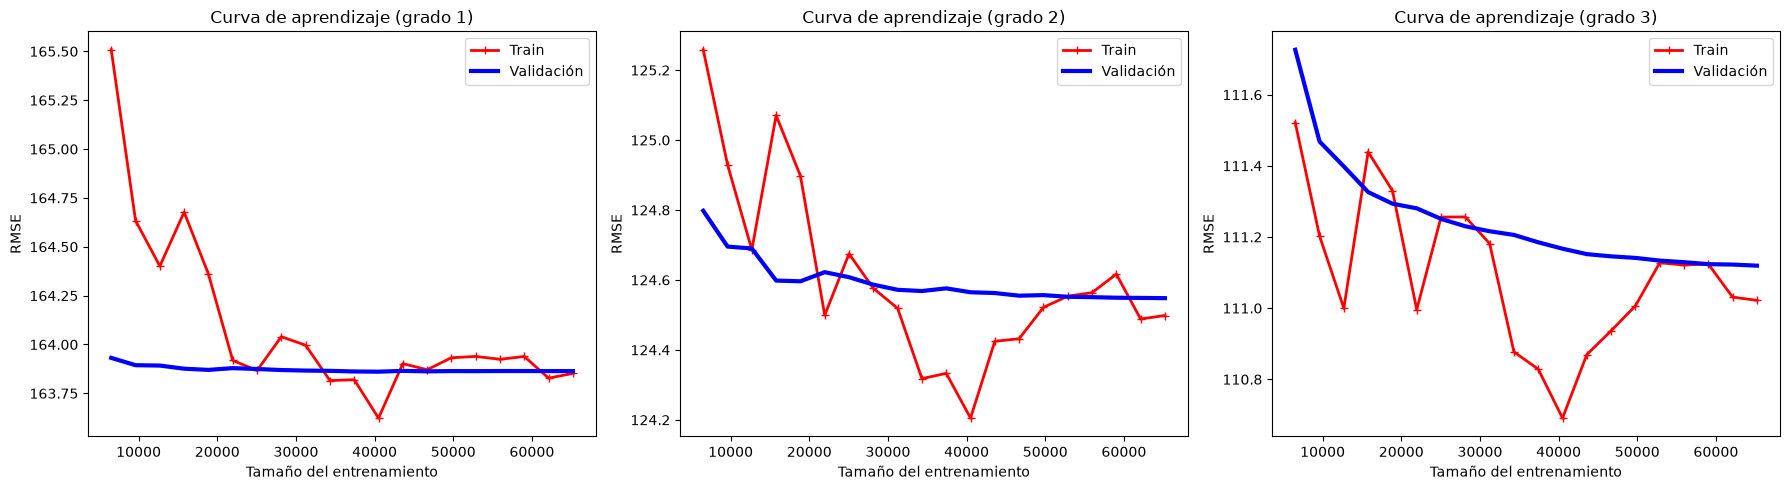

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

def curva_aprendizaje(X, y, grado, ax):
    """Dibuja la curva de aprendizaje de una regresión polinómica."""

    # Generamos las variables polinómicas
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_poly = poly.fit_transform(X)

    # Calculamos la curva de aprendizaje
    train_sizes, train_scores, valid_scores = learning_curve(
        LinearRegression(),
        X_poly,
        y,
        train_sizes=np.linspace(0.1, 1.0, 20),
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        scoring="neg_root_mean_squared_error"
    )

    # Calculamos los errores medios
    train_errors = -train_scores.mean(axis=1)
    valid_errors = -valid_scores.mean(axis=1)

    # Dibujamos las curvas
    ax.plot(train_sizes, train_errors, "r-+", linewidth=2, label="Train")
    ax.plot(train_sizes, valid_errors, "b-", linewidth=3, label="Validación")

    ax.set_xlabel("Tamaño del entrenamiento")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Curva de aprendizaje (grado {grado})")
    ax.legend()

# Creamos tres gráficos, uno para cada grado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Utilizamos únicamente los datos de entrenamiento
for ax, grado in zip(axes, [1, 2, 3]):
    curva_aprendizaje(X_train, y_train, grado, ax)

plt.tight_layout()
plt.show()

### REGULARIZACIÓN

In [41]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import RidgeCV

# Lo primero que hacemos es entrenar modelos con ridge con diferentes valores de alpha y evaluarlos por validación cruzada
modelo_ridgecv = RidgeCV(
            alphas           = np.logspace(-20, 2, 200),
            scoring          ='neg_root_mean_squared_error',
            fit_intercept    = True,
            store_cv_results = True
         )

_ = modelo_ridgecv.fit(X = X_train_scaled, y = y_train)

In [42]:
modelo_ridgecv.alpha_

13.04901978014407

In [43]:
# Hacemos el modelo con regularización con el valor de alpha que reduce más el error respecto al modelo sin regularización

# Train the model  
ridgeR = Ridge(alpha = modelo_ridgecv.alpha_) 
ridgeR.fit(X_train_scaled, y_train) 

print("Train RMSE: %0.4f" % root_mean_squared_error(y_train, ridgeR.predict(X_train_scaled)))
print("Test RMSE: %0.4f" % root_mean_squared_error(y_test, ridgeR.predict(X_test_scaled)))

Train RMSE: 163.8539
Test RMSE: 165.2182


In [45]:
df_coeficientes = pd.DataFrame({'predictor': X_train.columns,'coef':ridgeR.coef_.flatten()})

fig, ax = plt.subplots(figsize=(15, 10))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation=90, ha='right', size=6)
ax.set_xlabel('variable')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo')

AttributeError: 'numpy.ndarray' object has no attribute 'columns'